# Pipeline Graphics

This notebook only creates figures from saved MWIS artifacts. It does not rebuild the conflict graph or rerun decomposition.

The experiment is selected by `run_name_mwis` in `results/_config.json`, matching the MWIS pipeline. The input dataset and configuration displayed below come from the saved run, not from the current experiment parameters. Each figure includes the selected run name.

In [1]:
from __future__ import annotations

import json
import random
from pathlib import Path

missing_packages = []
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    missing_packages.append("matplotlib")
try:
    import networkx as nx
except ModuleNotFoundError:
    missing_packages.append("networkx")
try:
    import pandas as pd
except ModuleNotFoundError:
    missing_packages.append("pandas")

if missing_packages:
    packages = " ".join(missing_packages)
    raise ModuleNotFoundError(
        f"Missing notebook dependencies: {packages}. "
        f"Run `%pip install {packages}` in a notebook cell, then restart the kernel and rerun this notebook."
    )

def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root so paths work from either `results/` or `results/mwis/`."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "data").exists() and (candidate / "results").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing both `data/` and `results/`.")


PROJECT_ROOT = find_project_root()
RESULTS_DIR = PROJECT_ROOT / "results"

CONFIG_PATH = RESULTS_DIR / "_config.json"
run_config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
RUN_NAME = run_config["run_name_mwis"]
RUN_DIR = RESULTS_DIR / "runs" / "mwis_pipeline" / RUN_NAME

# Describe the experiment that produced these artifacts, even if current parameters changed.
SAVED_CONFIG_PATH = RUN_DIR / "run_config_log.json"
if not SAVED_CONFIG_PATH.exists():
    SAVED_CONFIG_PATH = RUN_DIR / "run_config.json"  # Older MWIS runs.
if not SAVED_CONFIG_PATH.exists():
    raise FileNotFoundError(f"No saved MWIS configuration in {RUN_DIR}. Run the MWIS pipeline for this experiment first.")
saved_run_config = json.loads(SAVED_CONFIG_PATH.read_text(encoding="utf-8"))
print(f"MWIS experiment: {RUN_NAME}")
print(f"Input dataset used: {saved_run_config['candidate_slot_csv']}")
print(f"Saved configuration from: {SAVED_CONFIG_PATH.resolve()}")
print(json.dumps(saved_run_config, indent=2))

FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

nodes = pd.read_csv(RUN_DIR / "conflict_graph_nodes.csv")
edges = pd.read_csv(RUN_DIR / "conflict_graph_edges.csv")
components = pd.read_csv(RUN_DIR / "components_summary.csv")
decomposition = pd.read_csv(RUN_DIR / "decomposition_summary.csv")
final_summary = pd.read_csv(RUN_DIR / "final_summary.csv")
solution = pd.read_csv(RUN_DIR / "mwis_solution.csv")
terminal_subgraphs = json.loads((RUN_DIR / "terminal_subgraphs.json").read_text(encoding="utf-8"))

print({"loaded_run": str(RUN_DIR), "nodes": len(nodes), "edges": len(edges), "terminal_subgraphs": len(terminal_subgraphs)})

{'loaded_run': 'C:\\Users\\felip\\Documents\\Polimi\\Semester 3\\SE2 Quantum Satisfiability Project\\satelite-optimization-quantum-annealing\\PoliMi-SWE2-research-project\\results\\runs\\mwis_pipeline\\latest_mwis_run', 'nodes': 533, 'edges': 1994, 'terminal_subgraphs': 72}


## Natural components by size

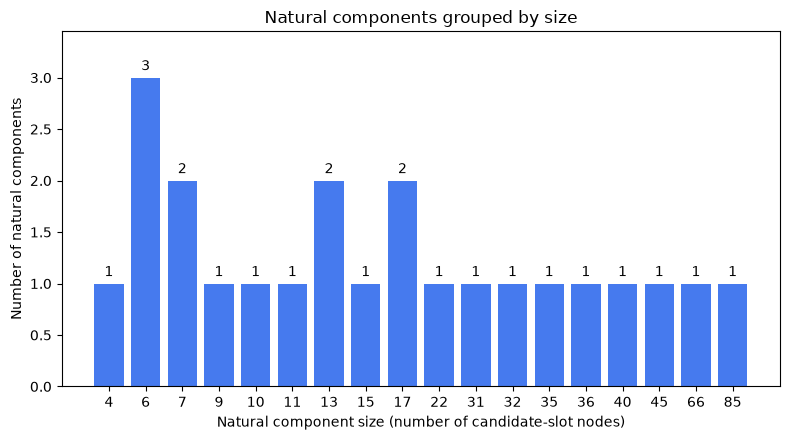

C:\Users\felip\Documents\Polimi\Semester 3\SE2 Quantum Satisfiability Project\satelite-optimization-quantum-annealing\PoliMi-SWE2-research-project\results\runs\mwis_pipeline\latest_mwis_run\figures\component_size_distribution.png


In [2]:
size_counts = components["node_count"].value_counts().sort_index()

plt.figure(figsize=(8, 4.5))
bars = plt.bar(size_counts.index.astype(str), size_counts.values, color="#2563eb", alpha=0.85)
plt.xlabel("Natural component size (number of candidate-slot nodes)")
plt.ylabel("Number of natural components")
plt.title(f"Natural components grouped by size\nMWIS experiment: {RUN_NAME}")
plt.bar_label(bars, labels=[str(value) for value in size_counts.values], padding=3)
plt.ylim(0, max(size_counts.values) * 1.15)
plt.tight_layout()
path = FIGURE_DIR / "component_size_distribution.png"
plt.savefig(path, dpi=200)
plt.show()
print(path)

## Subgraph provenance

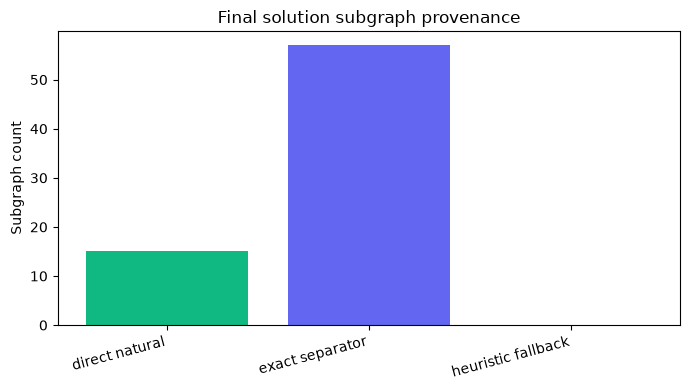

C:\Users\felip\Documents\Polimi\Semester 3\SE2 Quantum Satisfiability Project\satelite-optimization-quantum-annealing\PoliMi-SWE2-research-project\results\runs\mwis_pipeline\latest_mwis_run\figures\subgraph_provenance.png


In [3]:
def summary_value(metric: str):
    row = final_summary[final_summary["metric"] == metric]
    if row.empty:
        return 0
    value = row.iloc[0]["value"]
    try:
        return float(value)
    except Exception:
        return value

provenance = pd.DataFrame([
    {"provenance": "direct natural", "count": summary_value("Subgraphs solved directly")},
    {"provenance": "exact separator", "count": summary_value("Subgraphs solved exactly with separator decomposition")},
    {"provenance": "heuristic fallback", "count": summary_value("Subgraphs solved heuristically")},
])

plt.figure(figsize=(7, 4))
colors = ["#10b981", "#6366f1", "#f43f5e"]
plt.bar(provenance["provenance"], provenance["count"], color=colors)
plt.ylabel("Subgraph count")
plt.title(f"Final solution subgraph provenance\nMWIS experiment: {RUN_NAME}")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
path = FIGURE_DIR / "subgraph_provenance.png"
plt.savefig(path, dpi=200)
plt.show()
print(path)

## Objective and bounds

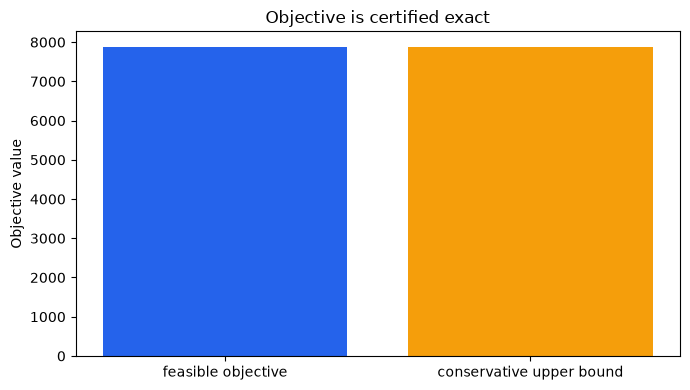

C:\Users\felip\Documents\Polimi\Semester 3\SE2 Quantum Satisfiability Project\satelite-optimization-quantum-annealing\PoliMi-SWE2-research-project\results\runs\mwis_pipeline\latest_mwis_run\figures\objective_bounds.png


In [4]:
objective = float(summary_value("Total feasible objective / lower bound"))
upper = float(summary_value("Total conservative upper bound"))
gap = float(summary_value("Absolute optimality-gap bound"))

plt.figure(figsize=(7, 4))
plt.bar(["feasible objective", "conservative upper bound"], [objective, upper], color=["#2563eb", "#f59e0b"])
if gap > 1e-9:
    plt.title(f"Objective lower bound and conservative upper bound (gap <= {gap:.2f})\nMWIS experiment: {RUN_NAME}")
else:
    plt.title(f"Objective is certified exact\nMWIS experiment: {RUN_NAME}")
plt.ylabel("Objective value")
plt.tight_layout()
path = FIGURE_DIR / "objective_bounds.png"
plt.savefig(path, dpi=200)
plt.show()
print(path)

## Example terminal subgraph

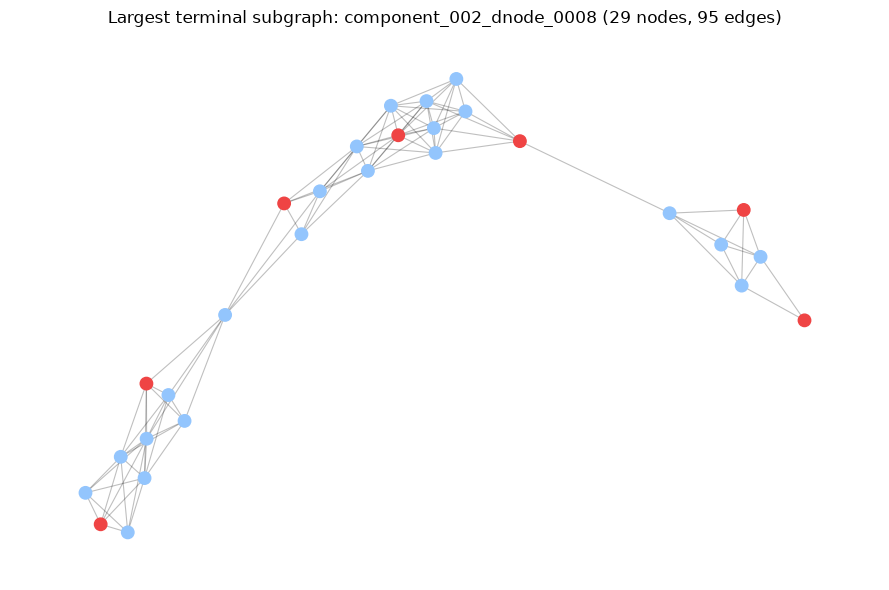

C:\Users\felip\Documents\Polimi\Semester 3\SE2 Quantum Satisfiability Project\satelite-optimization-quantum-annealing\PoliMi-SWE2-research-project\results\runs\mwis_pipeline\latest_mwis_run\figures\example_terminal_subgraph.png


In [5]:
def graph_from_terminal(record: dict) -> nx.Graph:
    graph = nx.Graph()
    for node in record["graph"]["nodes"]:
        node = dict(node)
        node_id = node.pop("id")
        graph.add_node(node_id, **node)
    for edge in record["graph"]["edges"]:
        edge = dict(edge)
        source = edge.pop("source")
        target = edge.pop("target")
        graph.add_edge(source, target, **edge)
    return graph

if terminal_subgraphs:
    record = max(terminal_subgraphs, key=lambda item: (item["node_count"], item["edge_count"]))
    graph = graph_from_terminal(record)
    selected = set(solution["slot_id"])
    node_colors = ["#ef4444" if node in selected else "#93c5fd" for node in graph.nodes]
    plt.figure(figsize=(9, 6))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw_networkx_edges(graph, pos, alpha=0.25, width=0.8)
    nx.draw_networkx_nodes(graph, pos, node_color=node_colors, node_size=80)
    plt.title(f"Largest terminal subgraph: {record['terminal_id']} ({graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges)\nMWIS experiment: {RUN_NAME}")
    plt.axis("off")
    plt.tight_layout()
    path = FIGURE_DIR / "example_terminal_subgraph.png"
    plt.savefig(path, dpi=200)
    plt.show()
    print(path)
else:
    print("No terminal subgraphs available.")